In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_pump_calibration_func
importlib.reload(PaP_pump_calibration_func)
from PaP_pump_calibration_func import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

# FWHM with lens position

### SMS map filename specification : 

the format is "pmmdd_n_desc_xlp2_xxmm_SOU_xxxnm"

p : first letter is p

mm : month (06, 10...)

dd : day (15, 22...)

n : scan number of the day

desc : anything to describe the scan (map size, sample characteristics...)

SOU : laser source (SGH, OPO, CHA, Maitai...)

xlps_xxmm : It is the position of the second pump lens screw (the optic used to monitor pump beam divergence). xx is the value of the position and mm is the unit read on the screw.

xxxnm : wavelength

## Get SMS map Data

In [2]:
# The path of the main directory
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-08\SHG calibration 410nm - different  pump lens position'
os.chdir(dir_root)

SMS_data = get_treated_SMS_maps(dir_root)

## Get FWHM with lens position

In [3]:
Lens_pos = []
FWHM = []

for key in SMS_data :
    sms = SMS_data[key]


    x_lp2 = float(sms.fname.split('_')[-3][:-2]) #position of the lens
    print(x_lp2)
    Lens_pos.append(x_lp2)
    FWHM.append(sms.FWHM_1D)


Lens_pos = np.array(Lens_pos)
FWHM = np.array(FWHM)

idx_sorted = np.argsort(Lens_pos)

FWHM = FWHM[idx_sorted]
Lens_pos = Lens_pos[idx_sorted]

11.0
10.0
9.0
8.0
12.0
13.0


In [4]:
print(FWHM)

[261.96533229 268.5502591  269.80268304 270.85401633 286.62476999
 309.19399756]


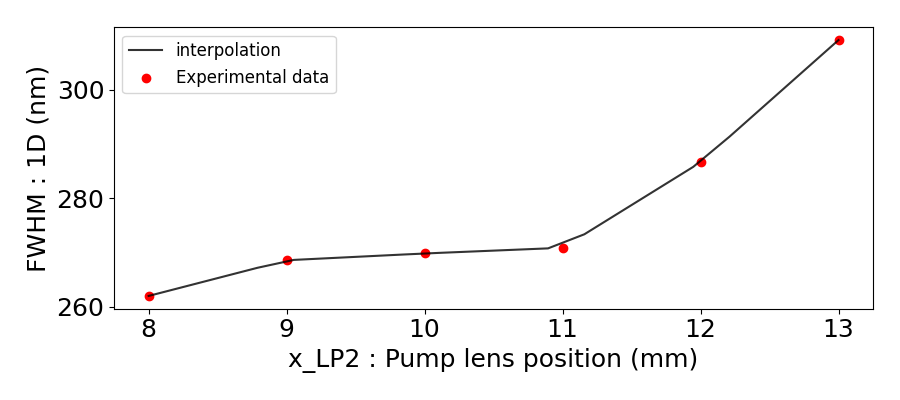

In [5]:
FWHM_interp = scipy.interpolate.interp1d(Lens_pos, FWHM)

X = np.linspace(Lens_pos.min(), Lens_pos.max(), 20)

fig, ax = plt.subplots(figsize = (9,4))

ax.plot(X, FWHM_interp(X), label='interpolation', color='black', alpha=0.8)

ax.scatter(Lens_pos, FWHM, label='Experimental data', color='red')

ax.set_xlabel('x_LP2 : Pump lens position (mm)')
ax.set_ylabel('FWHM : 1D (nm)')

plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

## Save data

In [6]:
Dic_dataframe = {
        'Lens position (nm)' : Lens_pos, \
        'FWHM (nm)' : FWHM, \
    }

os.chdir(dir_root)
df = pd.DataFrame(Dic_dataframe)
df.to_csv('Treated_data.csv', index=False)


Dic_dataframe2 = {
        'Lens position interpolation (nm)' : X, \
        'FWHM interpolation (nm)' : FWHM_interp(X), \
    }

os.chdir(dir_root)
df2 = pd.DataFrame(Dic_dataframe2)
df2.to_csv('Treated_data_interpolated.csv', index=False)

# Objective transmission with lens position

Get data

In [7]:
dir_root_T = r'H:\commun\Utilisateur FNO\Nathan\Experimental\Calibration\Nanoscope 2\2026-04\SHG calibration 410nm - different  pump lens position'


Lens_pos = np.array([9, 10, 11, 12, 13])
P_out = np.array([0.96, 1.19, 1.72, 2.25, 3.00])
P_in = np.array([6, 6, 6, 6, 6])

T = P_out/P_in

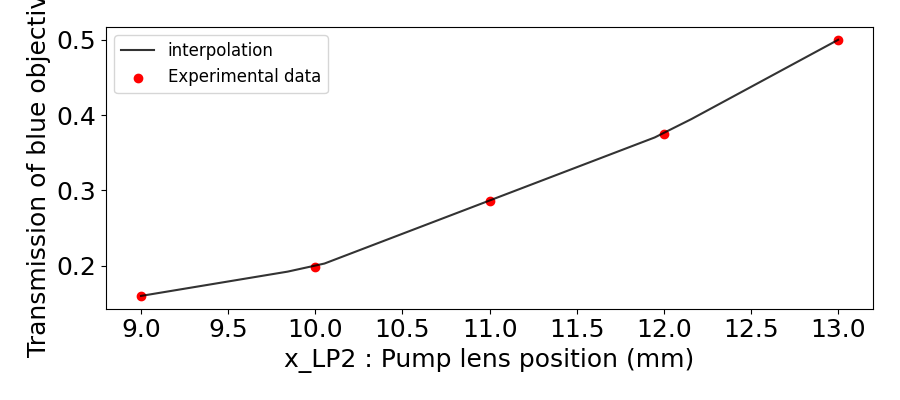

In [8]:
T_interp = scipy.interpolate.interp1d(Lens_pos, T)

X = np.linspace(Lens_pos.min(), Lens_pos.max(), 20)

fig, ax = plt.subplots(figsize = (9,4))

ax.plot(X, T_interp(X), label='interpolation', color='black', alpha=0.8)

ax.scatter(Lens_pos, T, label='Experimental data', color='red')

ax.set_xlabel('x_LP2 : Pump lens position (mm)')
ax.set_ylabel('Transmission of blue objective')

plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
Dic_dataframe = {
        'Lens position (nm)' : Lens_pos, \
        'Transmission(nm)' : T, \
    }

os.chdir(dir_root_T)
df = pd.DataFrame(Dic_dataframe)
df.to_csv('Objective Transmission.csv', index=False)